In [6]:
import numpy as np
import matplotlib.pyplot as plt
from dataloader import OceanDiffDataset, load_prog_mask, PROGNOSTIC_VARS, BOUNDARY_VARS, TRAIN_START, TRAIN_END

def draw(data, mask=None, title=None):
    data = np.squeeze(np.asarray(data))
    vmax = np.abs(data).max()
    plt.figure()
    im = plt.imshow(data, cmap='bwr', vmin=-vmax, vmax=vmax, interpolation='none', origin='lower')   # row 0 is the south pole
    if mask is not None:
        plt.contour(np.squeeze(mask), levels=[0.5], colors='k', linewidths=1)
    plt.colorbar(im)
    plt.title(title)
    plt.show()
    


In [7]:
ds = OceanDiffDataset(TRAIN_START, TRAIN_END)
mask = load_prog_mask()                      # (77, 180, 360)
state, forcing, datefrac = ds[0]             # (77, 180, 360), (3, 180, 360), ()
print(state.shape, forcing.shape, float(datefrac))

OceanDiffDataset: 4071 dates, 1958-01-03 .. 2013-10-05
torch.Size([77, 180, 360]) torch.Size([3, 180, 360]) 0.008219177834689617


In [23]:
mask.shape, forcing.shape

((77, 180, 360), torch.Size([3, 180, 360]))

In [10]:
a = np.load('/data/weidong/InMOS_1deg/SI_data/states.npy')
a.shape

(4745, 77, 180, 360)

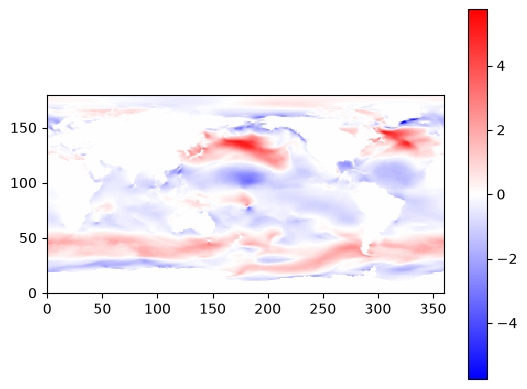

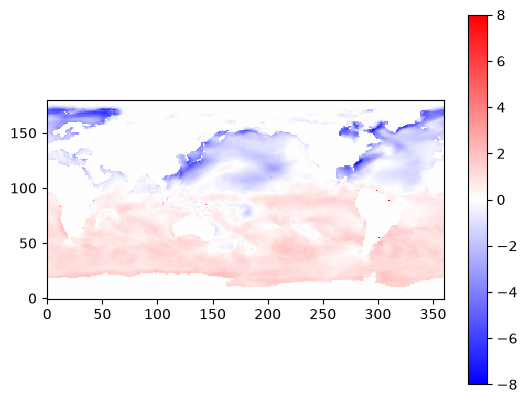

In [29]:
draw(forcing[2])

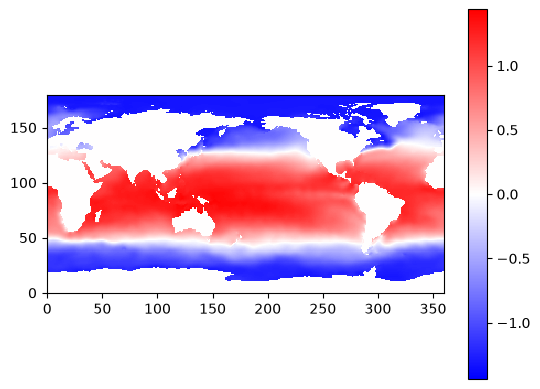

In [18]:
draw(a[0, 40])

In [22]:
c = PROGNOSTIC_VARS.index('thetao_0')
c

38

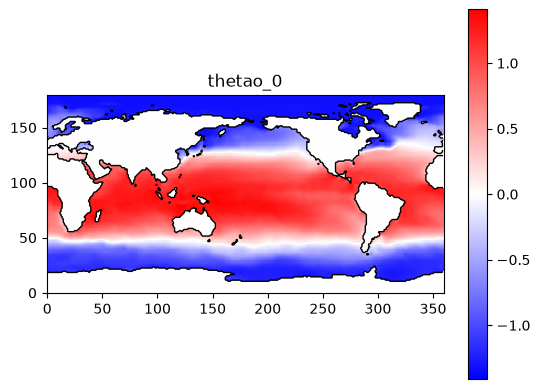

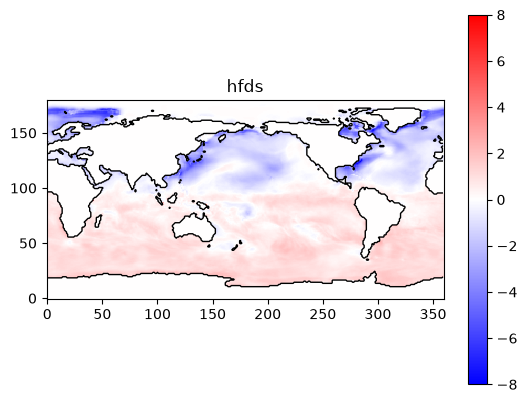

In [2]:
c = PROGNOSTIC_VARS.index('thetao_0')
draw(state[c], mask[c], 'thetao_0')
draw(forcing[2], mask[0], BOUNDARY_VARS[2])